In [8]:
from tkinter.ttk import Notebook
Notebook
%pip install pandas  
%pip install matplotlib

  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
    --------------------------------------- 0.3/11.0 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.0 MB 2.3 MB/s eta 0:00:05
   --------- ------------------------------ 2.6/11.0 MB 4.2 MB/s eta 0:00:02
   ---------------------- ----------------- 6.3/11.0 MB 7.9 MB/s eta 0:00:01
   ---------------------------------------  10.7/11.0 MB 11.0 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 9.1 MB/s  0:00:01
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.6 MB 16.9 MB/s eta 0:00:01
   --- ------------------------------------ 1.0/12.6 MB 3.1 MB/s eta 0:00:04
   ---- ----------------------------------

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.float_format', '{:,.2f}'.format)


In [20]:

candidates = [
    Path.cwd() / 'data' / 'sec_financials_2023_2025.csv',
    Path.cwd().parent / 'data' / 'sec_financials_2023_2025.csv',
]
file_path = next((p for p in candidates if p.is_file()), None)
if file_path is None:
    raise FileNotFoundError(f"Dataset not found. Notebook working directory: {Path.cwd()}; checked: {candidates}")
df = pd.read_csv(file_path)
df['Year'] = df['Year'].astype(int)
df = df.sort_values(['Company', 'Year']).reset_index(drop=True)
print('Loaded:', file_path)
print('Shape:', df.shape)
display(df)


Loaded: c:\Users\EMats\OneDrive\Desktop\SEC-Financial-Analysis\data\sec_financials_2023_2025.csv
Shape: (9, 7)


,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow
0,Apple,2023,383285,96995,352583,290437,110543
1,Apple,2024,391035,93736,364980,308030,118254
2,Apple,2025,416161,112010,359241,285508,111482
3,Microsoft,2023,211915,72361,411976,205753,87582
4,Microsoft,2024,245122,88136,512163,243686,118548
5,Microsoft,2025,281724,101832,619003,275524,136162
6,Tesla,2023,96773,14974,106618,43009,13256
7,Tesla,2024,97690,7153,122070,48390,14923
8,Tesla,2025,94827,3855,137806,54941,14747


In [23]:
metrics = ['Total Revenue', 'Net Income', 'Total Assets', 'Total Liabilities', 'Operating Cash Flow']
assert df.shape[0] == 9, 'Expected three companies x three years'
assert df[['Company', 'Year']].duplicated().sum() == 0
assert not df[metrics].isna().any().any()
assert set(df['Year']) == {2023, 2024, 2025}
print('Dataset validation passed.')

Dataset validation passed.


In [25]:
for metric in metrics:
    df[f'{metric} YoY %'] = df.groupby('Company')[metric].pct_change() * 100

df['Net Profit Margin %'] = df['Net Income'] / df['Total Revenue'] * 100
df['Liabilities to Assets %'] = df['Total Liabilities'] / df['Total Assets'] * 100
df['Operating Cash Flow / Net Income'] = df['Operating Cash Flow'] / df['Net Income']
display(df.round(2))

,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow,Total Revenue YoY %,Net Income YoY %,Total Assets YoY %,Total Liabilities YoY %,Operating Cash Flow YoY %,Net Profit Margin %,Liabilities to Assets %,Operating Cash Flow / Net Income
0,Apple,2023,383285,96995,352583,290437,110543,NaN,NaN,NaN,NaN,NaN,25.31,82.37,1.14
1,Apple,2024,391035,93736,364980,308030,118254,2.02,-3.36,3.52,6.06,6.98,23.97,84.40,1.26
2,Apple,2025,416161,112010,359241,285508,111482,6.43,19.50,-1.57,-7.31,-5.73,26.92,79.48,1.00
3,Microsoft,2023,211915,72361,411976,205753,87582,NaN,NaN,NaN,NaN,NaN,34.15,49.94,1.21
4,Microsoft,2024,245122,88136,512163,243686,118548,15.67,21.80,24.32,18.44,35.36,35.96,47.58,1.35
5,Microsoft,2025,281724,101832,619003,275524,136162,14.93,15.54,20.86,13.07,14.86,36.15,44.51,1.34
6,Tesla,2023,96773,14974,106618,43009,13256,NaN,NaN,NaN,NaN,NaN,15.47,40.34,0.89
7,Tesla,2024,97690,7153,122070,48390,14923,0.95,-52.23,14.49,12.51,12.58,7.32,39.64,2.09
8,Tesla,2025,94827,3855,137806,54941,14747,-2.93,-46.11,12.89,13.54,-1.18,4.07,39.87,3.83


In [27]:
summary_2025 = df[df['Year'] == 2025][['Company', *metrics, 'Net Profit Margin %', 'Liabilities to Assets %']]
display(summary_2025.sort_values('Total Revenue', ascending=False).round(2))

start = df[df['Year'] == 2023].set_index('Company')
end = df[df['Year'] == 2025].set_index('Company')
growth_23_25 = ((end[metrics] / start[metrics]) - 1) * 100
print('Total percentage change, FY2023 to FY2025:')
display(growth_23_25.round(2))

,Company,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow,Net Profit Margin %,Liabilities to Assets %
2,Apple,416161,112010,359241,285508,111482,26.92,79.48
5,Microsoft,281724,101832,619003,275524,136162,36.15,44.51
8,Tesla,94827,3855,137806,54941,14747,4.07,39.87


Total percentage change, FY2023 to FY2025:


,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow
Company,,,,,
Apple,8.58,15.48,1.89,-1.70,0.85
Microsoft,32.94,40.73,50.25,33.91,55.47
Tesla,-2.01,-74.26,29.25,27.74,11.25


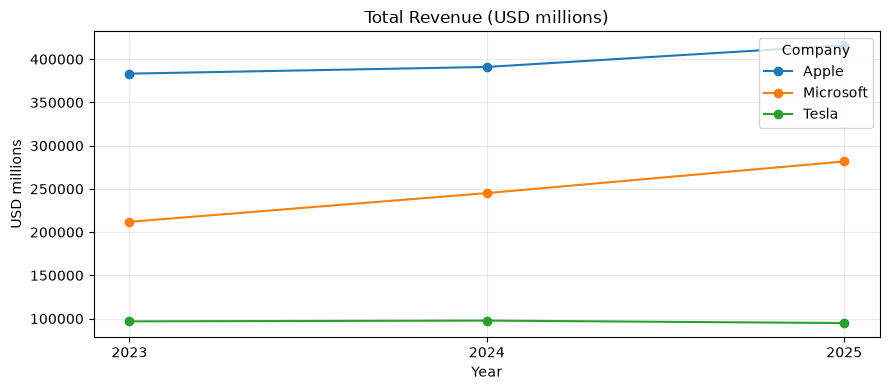

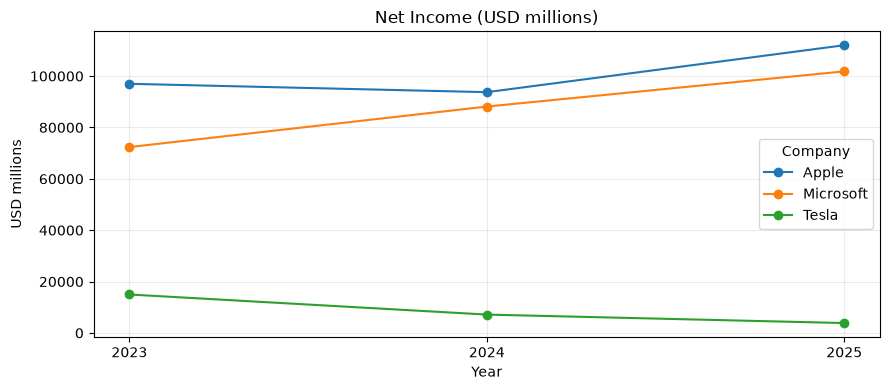

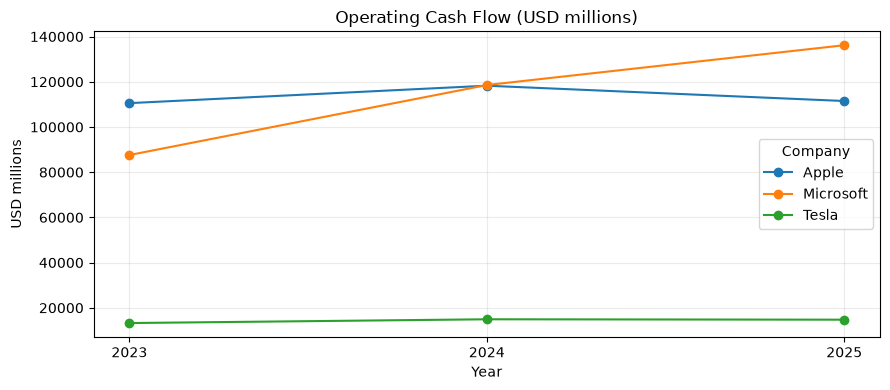

In [29]:
for metric in ['Total Revenue', 'Net Income', 'Operating Cash Flow']:
    pivot = df.pivot(index='Year', columns='Company', values=metric)
    ax = pivot.plot(marker='o', figsize=(9, 4), title=f'{metric} (USD millions)')
    ax.set_ylabel('USD millions')
    ax.set_xticks([2023, 2024, 2025])
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

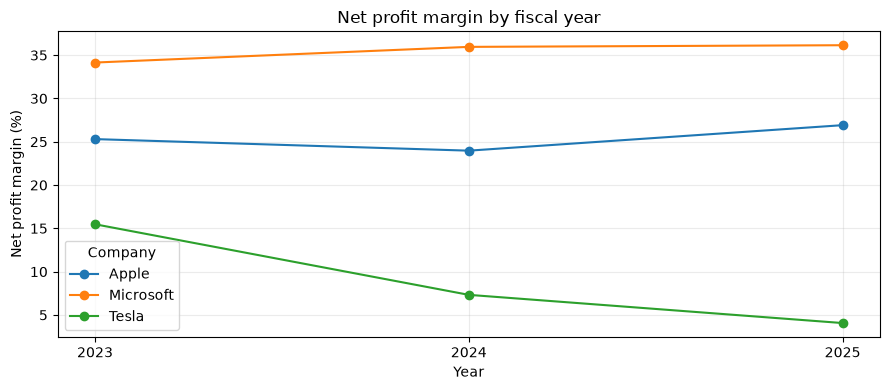

In [31]:
pivot = df.pivot(index='Year', columns='Company', values='Net Profit Margin %')
ax = pivot.plot(marker='o', figsize=(9, 4), title='Net profit margin by fiscal year')
ax.set_ylabel('Net profit margin (%)')
ax.set_xticks([2023, 2024, 2025])
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Findings and interpretation
Microsoft: Revenue rose from $211,915m to $281,724m (+32.9%) and net income from $72,361m to $101,832m (+40.7%) across FY2023–FY2025. Net income grew faster than revenue, indicating improved net profitability over this period.

Tesla: Revenue fell from $96,773m to $94,827m (−2.0%), while net income fell from $14,974m to $3,855m (−74.3%). Its assets grew over the same period. The decline in profit is much steeper than the decline in sales; further investigation of expenses, tax effects and other income-statement items is needed before assigning causes.

Apple: Revenue increased from $383,285m to $416,161m (+8.6%), and net income from $96,995m to $112,010m (+15.5%). Operating cash flow stayed above $110,000m in all three years, though it fluctuated.

Comparability limitations: These firms operate with different business models, capital requirements, and fiscal-year ends. Percentage growth and profit margin are useful comparative measures, but should not be interpreted as complete measures of business performance. Cash flow and net income measure different things; neither should be substituted for the other.
7. Implications for an AI-powered financial chatbot
An AI-powered chatbot could use a structured, source-linked table to answer questions such as:
- “What was Microsoft's FY2025 revenue and how much did it grow year over year?”
- “How did Tesla's net profit margin change between FY2023 and FY2025?”
- “Which company had the highest operating cash flow in FY2025?”
The chatbot should retrieve numbers and compute answers deterministically with pandas or SQL, then use an LLM to explain them. Each answer should state the company, metric definition, fiscal year, USD units, formula where applicable, and original SEC filing reference. It should distinguish factual calculations from speculative explanations, and refuse to invent missing data.
8. Conclusion
Across FY2023–FY2025, Microsoft showed the strongest revenue growth of the three companies, Apple retained the highest absolute revenue, and Tesla experienced a substantial decline in net income. This exercise demonstrates how cleaned financial data, transparent formulas, and source attribution can support reliable financial question-answering systems.

Conclusion and chatbot implications
The analysis demonstrates that revenue growth, profitability, asset expansion, and cash generation can diverge. A financial chatbot should calculate answers from a defined table rather than inventing figures. For each response it should report the company, fiscal year, unit, formula, and filing source; distinguish consolidated net income from income attributable to shareholders; and warn when a value has not been verified against its SEC filing.

Limitations: Only three fiscal years and three companies are included. This is descriptive analysis, not a valuation, forecast, or investment recommendation. Fiscal-year end dates differ across companies. SEC-reported values and metric definitions should be independently checked before publication.